In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from matplotlib import font_manager
from matplotlib.ticker import FuncFormatter
from shapely.geometry import box
import geopandas as gpd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from matplotlib.colors import to_rgb

In [2]:
TEKSTBREEDTE = 108 / 25.4  # breedte van een afbeelding in het proefschrift (108 mm)
CORPS = 10           # lettergrootte van as-, legenda- en titeltekst (pt)
CORPS_KLEIN = 8.5    # lettergrootte van dichte labels en annotaties (pt)

# ── vaste kleuren per betekenis (gelijk in alle hoofdstukken) ─────────────
KLEUR_HOOFD = "#1A8259"                         # één reeks
KLEUR_VROEG, KLEUR_LAAT = "#A07FD8", "#1A8259"  # vroege / late periode
KLEUR_MIDDEN = "#E07B28"                        # tussenperiode (bij drie periodes)
KLEUR_DAG, KLEUR_NACHT = "#C98A3C", "#2A62A8"
KLEUR_MAN, KLEUR_VROUW = "#E100A3", "#3FB3CC"
KLEUR_WIJK = {1: "#2A62A8", 3: "#E07B28", 5: "#1BAF7A", 6: "#C2187F"}  # 5 = 5+11, 6 = 6+7



def komma_decimalen(fig):
    """Decimale komma in de standaard-asopmaak (ook kleurenschalen); eigen
    opmaak (FuncFormatter, vaste labels) blijft ongemoeid."""
    from matplotlib import ticker

    class Komma(ticker.Formatter):
        def __init__(self, basis):
            self.basis = basis
        def set_locs(self, locs):
            self.basis.set_locs(locs)
        def __call__(self, x, pos=None):
            return self.basis(x, pos).replace(".", ",")
        def get_offset(self):
            return self.basis.get_offset().replace(".", ",")

    for ax in fig.axes:
        for as_ in (ax.xaxis, ax.yaxis):
            for kies, zet in ((as_.get_major_formatter, as_.set_major_formatter),
                              (as_.get_minor_formatter, as_.set_minor_formatter)):
                f = kies()
                if isinstance(f, (ticker.ScalarFormatter, ticker.LogFormatter)):
                    f.axis = as_
                    zet(Komma(f))

def pas_breedte_aan(fig, doel=108 / 25.4, tight=None):
    """Maakt de figuur zo breed dat de opgeslagen afbeelding (ook met bbox 'tight')
    precies `doel` inch breed is. De letters blijven even groot; alleen het
    grafiekvlak wordt iets breder of smaller. Zet ook de decimalen op de assen
    om naar een komma."""
    import matplotlib as mpl
    komma_decimalen(fig)
    if tight is None:
        tight = mpl.rcParams["savefig.bbox"] == "tight"
    pad = mpl.rcParams["savefig.pad_inches"] if tight else 0
    oorspronkelijk = fig.get_figwidth()
    for _ in range(6):
        fig.canvas.draw()
        breedte = (fig.get_tightbbox().width if tight else fig.get_figwidth()) + 2 * pad
        if abs(breedte - doel) < 0.004:
            break
        nieuw = fig.get_figwidth() + (doel - breedte)
        if nieuw < 0.5 * doel:
            # een legende of label is op zich al breder dan het doel
            fig.set_figwidth(oorspronkelijk)
            print(f"Let op: figuur past niet binnen {doel * 25.4:.0f} mm; breedte niet aangepast.")
            break
        fig.set_figwidth(nieuw)

SERIF = "Libertinus Serif"
FONTMAP = Path("fonts") 

beschikbaar = {f.name for f in font_manager.fontManager.ttflist}
if SERIF not in beschikbaar:
    print(f"{SERIF} niet gevonden; matplotlib valt terug op CMU Serif.")

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": [SERIF, "CMU Serif", "DejaVu Serif"],
    "font.size": CORPS,
    "axes.titlesize": CORPS,
    "axes.labelsize": CORPS,
    "xtick.labelsize": CORPS,
    "ytick.labelsize": CORPS,
    "legend.fontsize": CORPS,
    "mathtext.fontset": "custom",
    "mathtext.rm": SERIF,
    "mathtext.it": f"{SERIF}:italic",
    "mathtext.bf": f"{SERIF}:bold",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.bbox": "tight",
    "savefig.transparent": True,
    "savefig.dpi": 300,
})

def figsize(fractie=1.0, ratio=0.58):
    breedte = TEKSTBREEDTE * fractie
    return (breedte, breedte * ratio)

DATA = Path("../../data/algemeen")
DATA_HOOFDSTUK = Path("../../data/H3")
FIGUREN = Path("../../fig/H3")
FIGUREN.mkdir(exist_ok=True)
TABELLEN = Path("../../tab/H3")

# ── eenvormige rasterlijnen in alle figuren ───────────────────────────────
import matplotlib as mpl
mpl.rcParams.update({
    "axes.grid": False,          # raster alleen waar het expliciet aangezet wordt
    "axes.axisbelow": True,      # raster achter de data
    "grid.color": "#96999B",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.5,
    "grid.linestyle": "-",
})


In [3]:
from matplotlib.font_manager import FontProperties, findfont
print(findfont(FontProperties(family="serif")).split("/")[-1])  # enkel de bestandsnaam

LibertinusSerif-Regular.otf


In [4]:
KLEUR_A = KLEUR_HOOFD
KLEUR_B = KLEUR_VROEG

meta_df = pd.read_csv(DATA_HOOFDSTUK / "IB-metadata-enriched.csv")
meta_df.columns

Index(['ID', 'archive_file', 'url-to-scan(pdf)', 'district', 'date_start',
       'date_end', 'midpoint_date', 'year', 'incident_count', 'page_count',
       'line_count', 'word_count', 'char_count', 'french_ngrams',
       'dutch_ngrams', 'total_ngrams', 'french_proportion', 'dutch_proportion',
       'confscore'],
      dtype='object')

In [5]:
UITGESLOTEN = {'MA#41579'} # hulpbureel Linkeroever
PERIODE = (1876, 1939)
WOI = (1914, 1918)                  

corpus = meta_df[meta_df['year'].between(*PERIODE)
            & ~meta_df['archive_file'].isin(UITGESLOTEN)].copy()

print(f"{len(corpus)} boeken met zwaartepunt in {PERIODE[0]}–{PERIODE[1]}")
print(f"{corpus['incident_count'].sum():,}".replace(',', '.'), "gebeurtenissen")

196 boeken met zwaartepunt in 1876–1939
296.784 gebeurtenissen


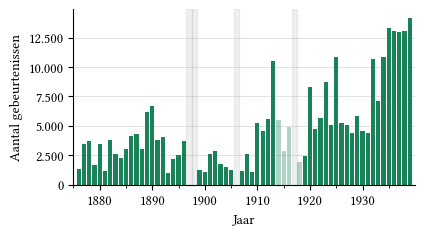

In [6]:
from matplotlib.ticker import FuncFormatter

NL_DUIZEND = FuncFormatter(lambda x, pos: f'{x:,.0f}'.replace(',', '.'))

# ── Corpusselectie uit de centrale cel ─────────────────────────────────
df_periode = corpus.copy()

gebeurtenissen = (
    df_periode.groupby('year')['incident_count'].sum().reset_index()
)

# ── Volledige jaarreeks, zodat ontbrekende jaren zichtbaar blijven ─────
jaren = pd.Series(range(PERIODE[0], PERIODE[1] + 1), name='year')
gebeurtenissen = (
    jaren.to_frame().merge(gebeurtenissen, on='year', how='left').fillna(0)
)

fig, ax = plt.subplots(figsize=(TEKSTBREEDTE, TEKSTBREEDTE * 0.58))

# ── Balken: oorlogsjaren bleker, want buiten de analyse ────────────────
is_woi = gebeurtenissen['year'].between(*WOI)

ax.bar(gebeurtenissen.loc[~is_woi, 'year'],
       gebeurtenissen.loc[~is_woi, 'incident_count'],
       width=0.8, color=KLEUR_A, linewidth=0)

ax.bar(gebeurtenissen.loc[is_woi, 'year'],
       gebeurtenissen.loc[is_woi, 'incident_count'],
       width=0.8, color=KLEUR_A, alpha=0.35, linewidth=0)

ax.set_xlabel('Jaar')
ax.set_ylabel('Aantal gebeurtenissen')
ax.yaxis.set_major_formatter(NL_DUIZEND)

# ── Jaren zonder boek met dat zwaartepunt ──────────────────────────────
for j in gebeurtenissen.loc[gebeurtenissen['incident_count'] == 0, 'year']:
    ax.axvspan(j - 0.5, j + 0.5, color='#96999B', alpha=0.15, zorder=0)

# ── Om de 5 jaar een tick, op de echte kalenderpositie ─────────────────
start = (PERIODE[0] // 5) * 5
ax.set_xticks(range(((PERIODE[0] + 9) // 10) * 10, PERIODE[1] + 1, 10))
ax.set_xticks(range(start, PERIODE[1] + 1, 5), minor=True)
ax.set_xlim(PERIODE[0] - 1, PERIODE[1] + 1)
ax.tick_params(axis='both', labelsize=CORPS)

ax.yaxis.grid(True)
ax.xaxis.grid(False)
ax.set_axisbelow(True)

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()

pas_breedte_aan(fig)
fig.savefig(FIGUREN / "3.5_aantal_geb_per_jaar.png", dpi=300)
plt.show()

In [7]:
CRS = "EPSG:31370"

# ── Opmaak ─────────────────────────────────────────────────────────────
mpl.rcParams.update({
    'font.family': 'STIX Two Text',
    'font.size': CORPS,
    'axes.titlesize': CORPS,
    'axes.unicode_minus': False,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'savefig.bbox': 'tight',
})

KLEUR_BEBOUWING = '#C8C8C8'
KLEUR_BEB_BOVEN = '#7A7A7A'
KLEUR_WATER = '#B8CDDD'
KLEUR_OMWALLING = '#4A4D4F'
KLEUR_WIJKGRENS = '#5A5E62'
ALPHA_BEB_BOVEN = 0.18


In [8]:
CRS = "EPSG:31370"

# ── Periodes en bijbehorende lagen ─────────────────────────────────────
PERIODES = [
    ('1876–1900', 1876, 1900, 1886, 'vroeg'),
    ('1901–1920', 1901, 1920, 1901, 'vroeg'),
    ('1921–1939', 1921, 1939, 1921, 'laat'),
]

GIS = DATA / "gis"
GEO = (".shp", ".gpkg", ".geojson")


def laad(map_, wat, jaar):
    """Bestandsnaam wat_jaar, waarbij jaar ook een periode kan zijn."""
    treffers = [p for p in sorted((GIS / map_).glob(f"{wat}_{jaar}*"))
                if p.suffix.lower() in GEO]
    if not treffers:
        raise FileNotFoundError(f"{wat}_{jaar} niet gevonden in {GIS / map_}")
    return gpd.read_file(treffers[0]).to_crs(CRS)


def selecteer_water(water, min_ha=3.0):
    """Houdt alle waterlichamen boven min_ha."""
    w = water.explode(index_parts=False).reset_index(drop=True)
    w["opp_ha"] = w.geometry.area / 1e4
    return w[w["opp_ha"] >= min_ha]


lagen = {
    "vesting": laad("bebouwing", "vesting", 1886),
    "fort":    laad("bebouwing", "vesting", 1908),
    "beb_v":   laad("bebouwing", "bebouwing", 1886),
    "beb_l":   laad("bebouwing", "bebouwing", 1908),
    "wat_v":   selecteer_water(laad("bebouwing", "water", 1886)),
    "wat_l":   selecteer_water(laad("bebouwing", "water", 1908)),
}

# ── Metadata: dezelfde selectie als de rest van het hoofdstuk ──────────
meta = corpus.copy()
# boeken die het Stadsarchief aan wijk 11 toekent, maar die vóór het bestaan van wijk 11
# vallen: geteld bij wijk 5, dat dit grondgebied toen bevatte (zie voetnoot bij Tabel 3.6)
meta.loc[meta['archive_file'].isin(['MA#33185', 'MA#33133', 'MA#33186']), 'district'] = 5


def wijkkolom_van(w):
    for kandidaat in ('SectionNr', 'Section_Nr', 'SECTIONNR'):
        if kandidaat in w.columns:
            return kandidaat
    raise KeyError(f'geen wijkkolom gevonden in {w.columns.tolist()}')


TOTAAL = meta['incident_count'].sum()
print(f"{len(meta)} boeken, {TOTAAL:,}".replace(',', '.'), "gebeurtenissen")


def aandeel_binnen_periode(wijken, van, tot):
    """Aandeel van alle gebeurtenissen in het corpus 1876-1939."""
    sel = meta[(meta['year'] >= van) & (meta['year'] <= tot)]
    tel = sel.groupby('district')['incident_count'].sum()

    w = wijken.copy()
    w['wijknr'] = pd.to_numeric(w[wijkkolom_van(w)], errors='coerce')
    w['aantal'] = w['wijknr'].map(tel).fillna(0)
    w['waarde'] = w['aantal'] / TOTAAL
    w['centroid'] = w.geometry.representative_point()

    if w['aantal'].sum() == 0:
        print(f'⚠ geen koppeling voor {van}–{tot}')
    return w


wijken_per_periode = [
    aandeel_binnen_periode(laad("wijken", "wijken", wijkjaar), van, tot)
    for _, van, tot, wijkjaar, _ in PERIODES
]

196 boeken. 296.784 gebeurtenissen


In [9]:
# ── Kaartvenster, gedeeld door alle panelen ────────────────────────────
alle_bounds = np.array(
    [w.total_bounds for w in wijken_per_periode]
    + [lagen["vesting"].total_bounds, lagen["fort"].total_bounds]
)
xmin, ymin = alle_bounds[:, 0].min(), alle_bounds[:, 1].min()
xmax, ymax = alle_bounds[:, 2].max(), alle_bounds[:, 3].max()

marge = 0.03 * max(xmax - xmin, ymax - ymin)
xmin, ymin, xmax, ymax = xmin - marge, ymin - marge, xmax + marge, ymax + marge

venster = gpd.GeoDataFrame(geometry=[box(xmin, ymin, xmax, ymax)], crs=CRS)
lagen = {n: gpd.clip(g, venster) for n, g in lagen.items()}

# ── Kleurschaal met aparte nulklasse ───────────────────────────────────
GRENZEN = [0.00, 0.01, 0.025, 0.05, 0.10, 0.25]
KLEUREN = ['#E8EFEB', '#B5CDC2', '#7BA593', '#487964', '#1C4536']
KLEUR_NUL = '#FFFFFF'


def kleur_van(waarde):
    if pd.isna(waarde) or waarde == 0:
        return KLEUR_NUL
    for boven, kleur in zip(GRENZEN[1:], KLEUREN):
        if waarde <= boven:
            return kleur
    return KLEUREN[-1]


def label_van(onder, boven):
    o = f'{onder*100:g}'.replace('.', ',')
    b = f'{boven*100:g}'.replace('.', ',')
    return f'{o}–{b}%'


legende = (
    [Patch(facecolor=KLEUR_NUL, edgecolor='none', label='0%')]
    + [Patch(facecolor=k, edgecolor='none',
             label=label_van(GRENZEN[i], GRENZEN[i + 1]))
       for i, k in enumerate(KLEUREN)]
)


# ── Schaalbalk en noordpijl ────────────────────────────────────────────
def schaalbalk(ax, x_frac=0.70, y_frac=0.05, lengte_m=1000,
               hoogte_frac=0.008, kleur='#1a1a1a'):
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    x = x0 + x_frac * (x1 - x0)
    y = y0 + y_frac * (y1 - y0)
    h = hoogte_frac * (y1 - y0)

    for i, kl in enumerate([kleur, 'white']):
        ax.add_patch(Rectangle((x + i * lengte_m / 2, y), lengte_m / 2, h,
                               facecolor=kl, edgecolor=kleur,
                               linewidth=0.4, zorder=8))

    label = f'{lengte_m} m' if lengte_m < 1000 else f'{lengte_m // 1000} km'
    ax.text(x + lengte_m / 2, y + h * 1.8, label,
            ha='center', va='bottom', fontsize=CORPS_KLEIN, color=kleur, zorder=8)


def noordpijl(ax, x_frac=0.92, y_frac=0.12, lengte_frac=0.05, kleur='#1a1a1a'):
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    x = x0 + x_frac * (x1 - x0)
    y = y0 + y_frac * (y1 - y0)
    lengte = lengte_frac * (y1 - y0)

    ax.annotate('', xy=(x, y + lengte), xytext=(x, y),
                arrowprops=dict(arrowstyle='-|>', color=kleur,
                                linewidth=0.8, mutation_scale=8), zorder=8)
    ax.text(x, y + lengte * 1.15, 'N', ha='center', va='bottom',
            fontsize=CORPS_KLEIN, color=kleur, zorder=8)

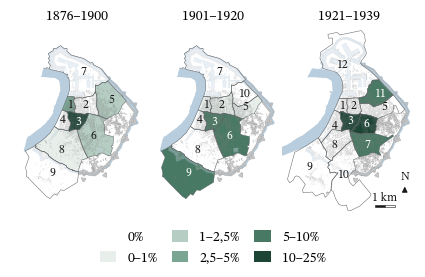

In [10]:
# ── Tekenen ────────────────────────────────────────────────────────────
fig_hoogte = (TEKSTBREEDTE / 3) * ((ymax - ymin) / (xmax - xmin)) * 1.08

fig, axes = plt.subplots(1, 3, figsize=(TEKSTBREEDTE, fig_hoogte),
                         gridspec_kw={'wspace': 0.02})

for ax, wijken, (titel, van, tot, shp, tijdvak) in zip(
        axes, wijken_per_periode, PERIODES):

    beb = lagen["beb_v"] if tijdvak == 'vroeg' else lagen["beb_l"]
    wat = lagen["wat_v"] if tijdvak == 'vroeg' else lagen["wat_l"]
    omw = lagen["vesting"] if tijdvak == 'vroeg' else lagen["fort"]

    ALPHA_BOVEN = 0.30

    # ── Onderlaag: dekkend, zodat de kleuren buiten de wijken vol blijven ──
    beb.plot(ax=ax, color=KLEUR_BEBOUWING, edgecolor='none',
             linewidth=0, zorder=1)
    wat.plot(ax=ax, color=KLEUR_WATER, edgecolor=KLEUR_WATER,
             linewidth=0.4, zorder=1)
    omw.plot(ax=ax, facecolor=KLEUR_BEBOUWING, edgecolor='#9A9A9A',
             linewidth=0.3, zorder=1)

    # ── Wijkvlakken ────────────────────────────────────────────────────
    for _, row in wijken.iterrows():
        gpd.GeoSeries([row.geometry], crs=CRS).plot(
            ax=ax, color=kleur_van(row["waarde"]),
            edgecolor='none', zorder=2)

    # ── Bovenlaag: transparant, laat het wijkgroen doorschemeren ───────
    beb.plot(ax=ax, color=KLEUR_BEB_BOVEN, edgecolor='none',
             linewidth=0, alpha=ALPHA_BOVEN, zorder=3)
    wat.plot(ax=ax, color=KLEUR_WATER, edgecolor=KLEUR_WATER,
             linewidth=0.4, alpha=ALPHA_BOVEN, zorder=4)
    omw.plot(ax=ax, facecolor=KLEUR_BEBOUWING, edgecolor='none',
             linewidth=0.4, alpha=ALPHA_BOVEN, zorder=5)

    wijken.boundary.plot(ax=ax, color=KLEUR_WIJKGRENS, linewidth=0.35, zorder=6)
    for _, row in wijken.iterrows():
        if pd.isna(row['wijknr']):
            continue
        vulling = kleur_van(row['waarde'])
        r, g, b = to_rgb(vulling)
        tekstkleur = 'white' if (0.299*r + 0.587*g + 0.114*b) < 0.5 else '#1a1a1a'
        ax.annotate(int(row['wijknr']),
                    xy=(row['centroid'].x, row['centroid'].y),
                    ha='center', va='center', fontsize=CORPS_KLEIN,
                    color=tekstkleur, zorder=7)
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_aspect('equal')
    ax.set_axis_off()
    ax.set_title(titel, pad=4)

fig.legend(handles=legende,
           loc='upper center', bbox_to_anchor=(0.5, 0.02), frameon=False,
           ncol=3, fontsize=CORPS,
           handlelength=1.2, handleheight=0.9, columnspacing=1.0,
           borderpad=0.2)

schaalbalk(axes[2])
noordpijl(axes[2])

fig.subplots_adjust(left=0.01, right=0.99, top=0.93, bottom=0.02)
pas_breedte_aan(fig)
fig.savefig(FIGUREN / "3.6_geb_per_wijk.png", dpi=300)

plt.show()

In [11]:
PERIODES_TABEL = [(t.replace('–', '-'), v, tot) for t, v, tot, _, _ in PERIODES]

# Welke wijken bestonden in welke periode (uit de wijkindelingen)
BESTOND = {
    '1876-1900': {1, 2, 3, 4, 5, 6, 7, 8, 9},
    '1901-1920': {1, 2, 3, 4, 5, 6, 7, 8, 9, 10},
    '1921-1939': {1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12},
}


def tabel8(meta, decimalen=2):
    m = meta[meta['archive_file'].isin(set(corpus['archive_file']))]
    totaal = m['incident_count'].sum()

    tellingen = {}
    for titel, van, tot in PERIODES_TABEL:
        tellingen[titel] = (m[(m['year'] >= van) & (m['year'] <= tot)]
                            .groupby('district')['incident_count'].sum())

    alle_wijken = sorted(set().union(*BESTOND.values()))
    rijen = []

    for wijk in alle_wijken:
        rij = {'wijk': wijk}
        totaal_wijk = 0
        for titel, *_ in PERIODES_TABEL:
            if wijk not in BESTOND[titel]:
                rij[titel], rij[f'{titel} %'] = 'n.v.t.', ''
                continue
            n = int(tellingen[titel].get(wijk, 0))
            totaal_wijk += n
            if n == 0:
                rij[titel], rij[f'{titel} %'] = '–', '–'
            else:
                rij[titel] = f'{n:,}'.replace(',', '.')
                rij[f'{titel} %'] = f'{n / totaal * 100:.{decimalen}f}'.replace('.', ',') + '%'

        if totaal_wijk == 0:
            rij['Tot'], rij['Tot %'] = '–', '–'
        else:
            rij['Tot'] = f'{totaal_wijk:,}'.replace(',', '.')
            rij['Tot %'] = f'{totaal_wijk / totaal * 100:.{decimalen}f}'.replace('.', ',') + '%'
        rijen.append(rij)

    # ── Totaalrij ──────────────────────────────────────────────────────
    slot = {'wijk': 'Tot'}
    for titel, *_ in PERIODES_TABEL:
        n = int(tellingen[titel].sum())
        slot[titel] = f'{n:,}'.replace(',', '.')
        slot[f'{titel} %'] = f'{n / totaal * 100:.{decimalen}f}'.replace('.', ',') + '%'
    slot['Tot'] = f'{totaal:,}'.replace(',', '.')
    slot['Tot %'] = '100%'
    rijen.append(slot)

    kolommen = ['wijk']
    for titel, *_ in PERIODES_TABEL:
        kolommen += [titel, f'{titel} %']
    kolommen += ['Tot', 'Tot %']

    tab = pd.DataFrame(rijen)[kolommen]

    print(f'corpus: {len(m)} boeken, {totaal:,} gebeurtenissen'.replace(',', '.'))
    print(tab.to_string(index=False))
    return tab


tab8 = tabel8(meta)
tab8.to_csv(TABELLEN / "3.6_gebeurtenissen_per_wijk.csv", index=False)

corpus: 196 boeken. 296.784 gebeurtenissen
wijk 1876-1900 1876-1900 % 1901-1920 1901-1920 % 1921-1939 1921-1939 %     Tot  Tot %
   1    13.558       4,57%     2.613       0,88%         –           –  16.171  5,45%
   2         –           –     1.508       0,51%         –           –   1.508  0,51%
   3    45.663      15,39%    18.782       6,33%    63.214      21,30% 127.659 43,01%
   4         –           –         –           –         –           –       –      –
   5     4.507       1,52%     2.916       0,98%         –           –   7.423  2,50%
   6     4.623       1,56%    20.065       6,76%    49.523      16,69%  74.211 25,01%
   7         –           –         –           –    17.482       5,89%  17.482  5,89%
   8     2.064       0,70%         –           –         –           –   2.064  0,70%
   9         –           –    20.903       7,04%         –           –  20.903  7,04%
  10    n.v.t.                     –           –         –           –       –      –
  11    n.v

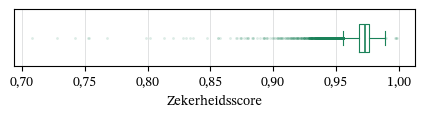

count    87622.000000
mean         0.971656
std          0.008094
min          0.707986
25%          0.968373
50%          0.973170
75%          0.976764
max          0.998620
Name: conf_score, dtype: float64

In [12]:
NL_DECIMAAL = FuncFormatter(lambda x, pos: f'{x:.2f}'.replace('.', ','))

df_confscore_page = pd.read_csv(DATA_HOOFDSTUK / 'IB-confscore_page.csv')
df_confscore_page['conf_score'] = pd.to_numeric(
    df_confscore_page['confscore'], errors='coerce'
)

fig, ax = plt.subplots(figsize=(TEKSTBREEDTE, TEKSTBREEDTE * 0.3))

boxprops = dict(linewidth=0.8, color=KLEUR_A)
medianprops = dict(linewidth=1.2, color=KLEUR_A)
flierprops = dict(marker='o', markersize=2, markerfacecolor=KLEUR_A,
                  markeredgecolor='none', alpha=0.15)
whiskerprops = dict(color=KLEUR_A, linewidth=0.8)
capprops = dict(color=KLEUR_A, linewidth=0.8)

df_confscore_page.boxplot(
    column='conf_score', grid=False,
    boxprops=boxprops, medianprops=medianprops, flierprops=flierprops,
    whiskerprops=whiskerprops, capprops=capprops,
    vert=False, widths=0.5, ax=ax
)

ax.set_ylim(0.5, 1.5)
ax.set_xlabel('Zekerheidsscore')
ax.xaxis.set_major_formatter(NL_DECIMAAL)
ax.set_yticks([])
ax.set_title('')

ax.xaxis.grid(True)
ax.set_axisbelow(True)

plt.tight_layout()

pas_breedte_aan(fig)
fig.savefig(FIGUREN / "3.8_boxplot_zekerheidsscore.png", dpi=300)
plt.show()
df_confscore_page['conf_score'].describe()

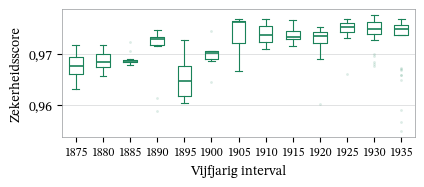

In [13]:
df_periode = corpus.copy()
df_periode['conf_score'] = pd.to_numeric(df_periode['confscore'], errors='coerce')
df_periode['interval'] = (df_periode['year'] // 5) * 5

fig, ax = plt.subplots(figsize=(TEKSTBREEDTE, TEKSTBREEDTE * 0.5))

df_periode.boxplot(
    column='conf_score', by='interval', grid=False,
    boxprops=dict(color=KLEUR_A, linewidth=0.8),
    whiskerprops=dict(color=KLEUR_A, linewidth=0.8),
    capprops=dict(color=KLEUR_A, linewidth=0.8),
    medianprops=dict(color=KLEUR_A, linewidth=1.2),
    flierprops=dict(marker='o', markersize=2, markerfacecolor=KLEUR_A,
                    markeredgecolor='none', alpha=0.15),
    ax=ax
)

ax.set_xlabel('Vijfjarig interval')
ax.set_ylabel('Zekerheidsscore')
ax.yaxis.set_major_formatter(NL_DECIMAAL)
ax.set_title('')
fig.suptitle('')

ax.tick_params(axis='x', rotation=0, labelsize=CORPS_KLEIN)
ax.tick_params(axis='y', labelsize=CORPS)

ax.yaxis.grid(True)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(0.5)
    spine.set_color('#96999B')

plt.tight_layout()

pas_breedte_aan(fig)
fig.savefig(FIGUREN / "3.9_boxplot_5j.png", dpi=300)

plt.show()